## Healthcare Appointment Attendance Analysis using Python

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 

In [2]:
df = pd.read_csv("appointments.csv")

In [3]:
df.head()

,PatientId,AppointmentID,Gender,ScheduledDay,AppointmentDay,Age,Neighbourhood,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,No-show
0,2.987250e+13,5642903,F,2016-04-29T18:38:08Z,2016-04-29T00:00:00Z,62,JARDIM DA PENHA,0,1,0,0,0,0,No
1,5.589980e+14,5642503,M,2016-04-29T16:08:27Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,0,0,0,0,0,No
2,4.262960e+12,5642549,F,2016-04-29T16:19:04Z,2016-04-29T00:00:00Z,62,MATA DA PRAIA,0,0,0,0,0,0,No
3,8.679510e+11,5642828,F,2016-04-29T17:29:31Z,2016-04-29T00:00:00Z,8,PONTAL DE CAMBURI,0,0,0,0,0,0,No
4,8.841190e+12,5642494,F,2016-04-29T16:07:23Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,1,1,0,0,0,No


In [4]:
df.shape

(110527, 14)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 110527 entries, 0 to 110526
Data columns (total 14 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   PatientId       110527 non-null  float64
 1   AppointmentID   110527 non-null  int64  
 2   Gender          110527 non-null  object 
 3   ScheduledDay    110527 non-null  object 
 4   AppointmentDay  110527 non-null  object 
 5   Age             110527 non-null  int64  
 6   Neighbourhood   110527 non-null  object 
 7   Scholarship     110527 non-null  int64  
 8   Hipertension    110527 non-null  int64  
 9   Diabetes        110527 non-null  int64  
 10  Alcoholism      110527 non-null  int64  
 11  Handcap         110527 non-null  int64  
 12  SMS_received    110527 non-null  int64  
 13  No-show         110527 non-null  object 
dtypes: float64(1), int64(8), object(5)
memory usage: 11.8+ MB


In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
print("Age range: ")
print(df["Age"].min(),"to", df["Age"].max())
print("\nGender Values: ")
print(df["Gender"].value_counts())
print("\nNo_Show Values: ")
print(df["No-show"].value_counts())
print("\nSMS Received Values: ")
print(df["SMS_received"])

Age range: 
-1 to 115

Gender Values: 
Gender
F    71840
M    38687
Name: count, dtype: int64

No_Show Values: 
No-show
No     88208
Yes    22319
Name: count, dtype: int64

SMS Received Values: 
0         0
1         0
2         0
3         0
4         0
         ..
110522    1
110523    1
110524    1
110525    1
110526    1
Name: SMS_received, Length: 110527, dtype: int64


In [8]:
print("SMS Received Counts:")
print(df["SMS_received"].value_counts())
print("\nInvalid Age Records:")
print(df[df["Age"] < 0])
print("\nAge Distribution:")
print(df["Age"].describe())

SMS Received Counts:
SMS_received
0    75045
1    35482
Name: count, dtype: int64

Invalid Age Records:
          PatientId  AppointmentID Gender          ScheduledDay  \
99832  4.659430e+14        5775010      F  2016-06-06T08:58:13Z   

             AppointmentDay  Age Neighbourhood  Scholarship  Hipertension  \
99832  2016-06-06T00:00:00Z   -1         ROMÃO            0             0   

       Diabetes  Alcoholism  Handcap  SMS_received No-show  
99832         0           0        0             0      No  

Age Distribution:
count    110527.000000
mean         37.088874
std          23.110205
min          -1.000000
25%          18.000000
50%          37.000000
75%          55.000000
max         115.000000
Name: Age, dtype: float64


In [30]:
df_clean = df.copy()
df_clean = df_clean[df_clean["Age"] >= 0].copy()
print("Original records: ", df.shape[0])
print("Cleaned records: ", df_clean.shape[0])
print("Invalid ages remaining: ",(df_clean["Age"] < 0).sum())

Original records:  110527
Cleaned records:  110526
Invalid ages remaining:  0


In [10]:
df_clean = df_clean.rename(columns={
    "PatientId": "patient_id",
    "AppointmentID": "appointment_id",
    "Gender": "gender",
    "ScheduledDay": "scheduled_day",
    "AppointmentDay": "appointment_day",
    "Age": "age",
    "Neighbourhood": "neighbourhood",
    "Scholarship": "scholarship",
    "Hipertension": "hypertension",
    "Diabetes": "diabetes",
    "Alcoholism": "alcoholism",
    "Handcap": "handicap",
    "SMS_received": "sms_received",
    "No-show": "no_show"
})
df_clean.columns

Index(['patient_id', 'appointment_id', 'gender', 'scheduled_day',
       'appointment_day', 'age', 'neighbourhood', 'scholarship',
       'hypertension', 'diabetes', 'alcoholism', 'handicap', 'sms_received',
       'no_show'],
      dtype='object')

In [11]:
df_clean["scheduled_day"] = pd.to_datetime(df_clean["scheduled_day"], utc=True)
df_clean["appointment_day"] = pd.to_datetime(df_clean["appointment_day"], utc=True)
df_clean[["scheduled_day", "appointment_day"]].dtypes

scheduled_day      datetime64[ns, UTC]
appointment_day    datetime64[ns, UTC]
dtype: object

In [12]:
df_clean["waiting_days"]=(df_clean["appointment_day"]
        - df_clean["scheduled_day"]).dt.total_seconds()/(24*60*60)
df_clean["waiting_days"].describe()

count    110526.000000
mean          9.714376
std          15.244112
min          -6.575926
25%          -0.346157
50%           3.473993
75%          14.320576
max         178.554873
Name: waiting_days, dtype: float64

In [13]:
df_clean["waiting_days"] = (
    df_clean["appointment_day"].dt.date
    - df_clean["scheduled_day"].dt.date
).apply(lambda x: x.days)

df_clean["waiting_days"].describe()

count    110526.000000
mean         10.183794
std          15.255034
min          -6.000000
25%           0.000000
50%           4.000000
75%          15.000000
max         179.000000
Name: waiting_days, dtype: float64

In [14]:
df_clean[df_clean["waiting_days"] < 0][
    ["scheduled_day", "appointment_day", "waiting_days"]
].head(10)

,scheduled_day,appointment_day,waiting_days
27033,2016-05-10 10:51:53+00:00,2016-05-09 00:00:00+00:00,-1
55226,2016-05-18 14:50:41+00:00,2016-05-17 00:00:00+00:00,-1
64175,2016-05-05 13:43:58+00:00,2016-05-04 00:00:00+00:00,-1
71533,2016-05-11 13:49:20+00:00,2016-05-05 00:00:00+00:00,-6
72362,2016-05-04 06:50:57+00:00,2016-05-03 00:00:00+00:00,-1


In [15]:
(df_clean["waiting_days"] < 0).sum()

np.int64(5)

In [16]:
df_analysis = df_clean[df_clean["waiting_days"] >= 0].copy()
print("Records before removal:", len(df_clean))
print("Records for analysis:", len(df_analysis))
print("Negative waiting times remaining:", (df_analysis["waiting_days"] < 0).sum())

Records before removal: 110526
Records for analysis: 110521
Negative waiting times remaining: 0


In [17]:
df_analysis["no_show"].value_counts()

no_show
No     88207
Yes    22314
Name: count, dtype: int64

In [18]:
no_show_counts = df_analysis["no_show"].value_counts()
attendance_rate = (no_show_counts["No"] / len(df_analysis)) * 100
no_show_rate = (no_show_counts["Yes"] / len(df_analysis)) * 100
print(f"Attendance rate: {attendance_rate:.2f}%")
print(f"No-show rate: {no_show_rate:.2f}%")

Attendance rate: 79.81%
No-show rate: 20.19%


In [19]:
df_analysis.groupby("gender")["no_show"].value_counts()

gender  no_show
F       No         57245
        Yes        14591
M       No         30962
        Yes         7723
Name: count, dtype: int64

In [20]:
gender_no_show = (df_analysis.groupby("gender")["no_show"]
    .apply(lambda x: (x == "Yes").mean() * 100))
print(gender_no_show.round(2))

gender
F    20.31
M    19.96
Name: no_show, dtype: float64


In [21]:
df_analysis["age_group"] = pd.cut(df_analysis["age"],
    bins=[-1, 17, 35, 55, 115],
    labels=["0–17", "18–35", "36–55", "56+"])
df_analysis.groupby("age_group", observed=False)["no_show"].apply(
    lambda x: (x == "Yes").mean() * 100
).round(2)

age_group
0–17     21.90
18–35    23.81
36–55    19.70
56+      15.64
Name: no_show, dtype: float64

In [22]:
df_analysis["no_show"].value_counts()

no_show
No     88207
Yes    22314
Name: count, dtype: int64

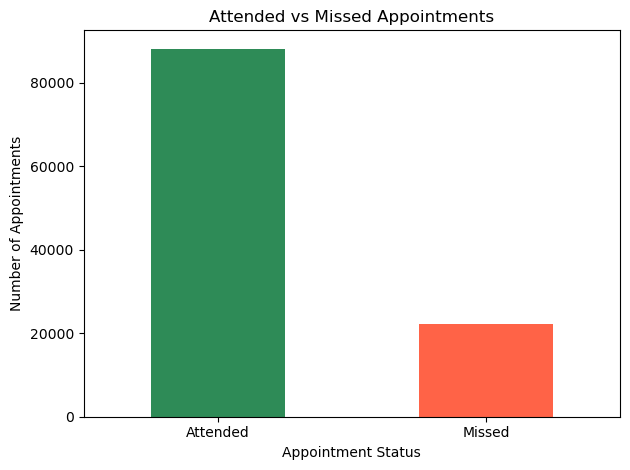

In [23]:
appointment_counts = df_analysis["no_show"].value_counts()
appointment_counts = appointment_counts.rename({
    "No": "Attended",
    "Yes": "Missed"
})
appointment_counts.plot(kind="bar", color=["seagreen", "tomato"])
plt.title("Attended vs Missed Appointments")
plt.xlabel("Appointment Status")
plt.ylabel("Number of Appointments")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

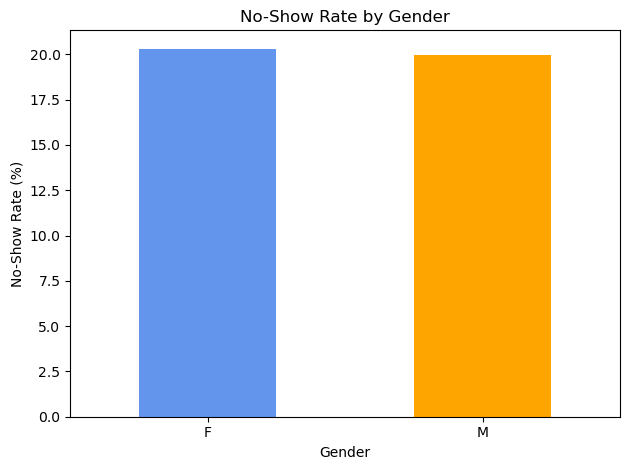

In [24]:
gender_no_show = (df_analysis.groupby("gender")["no_show"]
    .apply(lambda x: (x == "Yes").mean() * 100))
gender_no_show.plot(kind="bar", color=["cornflowerblue", "orange"])
plt.title("No-Show Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("No-Show Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

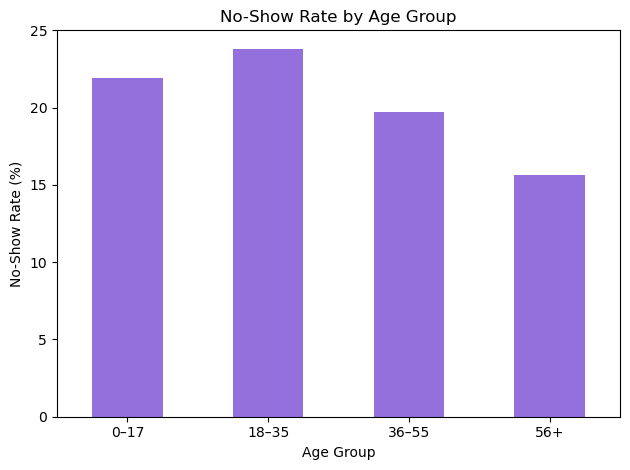

In [25]:
age_no_show = (df_analysis.groupby("age_group", observed=False)["no_show"]
    .apply(lambda x: (x == "Yes").mean() * 100))
age_no_show.plot(kind="bar", color="mediumpurple")
plt.title("No-Show Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("No-Show Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [26]:
sms_no_show = (df_analysis.groupby("sms_received")["no_show"]
    .apply(lambda x: (x == "Yes").mean() * 100))
sms_no_show.index = ["No SMS", "SMS Received"]
print(sms_no_show.round(2))

No SMS          16.70
SMS Received    27.57
Name: no_show, dtype: float64


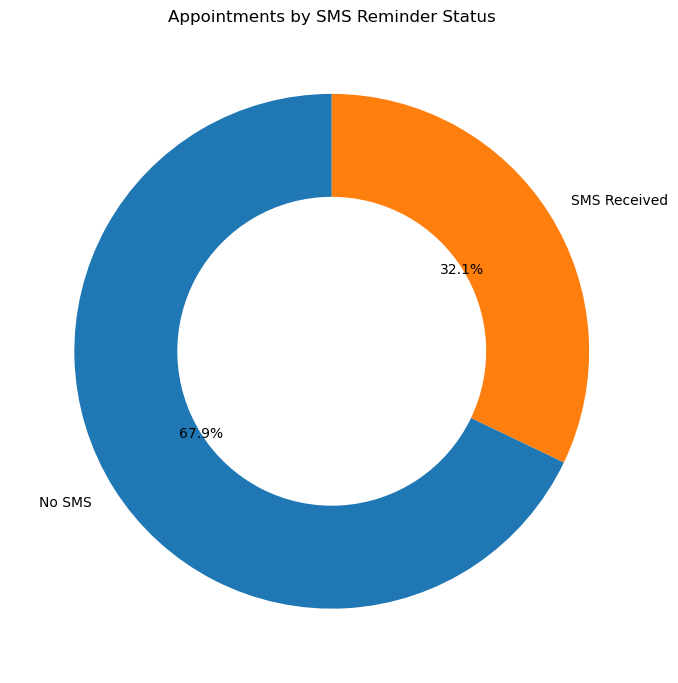

In [27]:
sms_counts = df_analysis["sms_received"].value_counts()
sms_counts.index = ["No SMS", "SMS Received"]
plt.figure(figsize=(7, 7))
plt.pie(
    sms_counts,
    labels=sms_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"width": 0.4}
)
plt.title("Appointments by SMS Reminder Status")
plt.tight_layout()
plt.show()

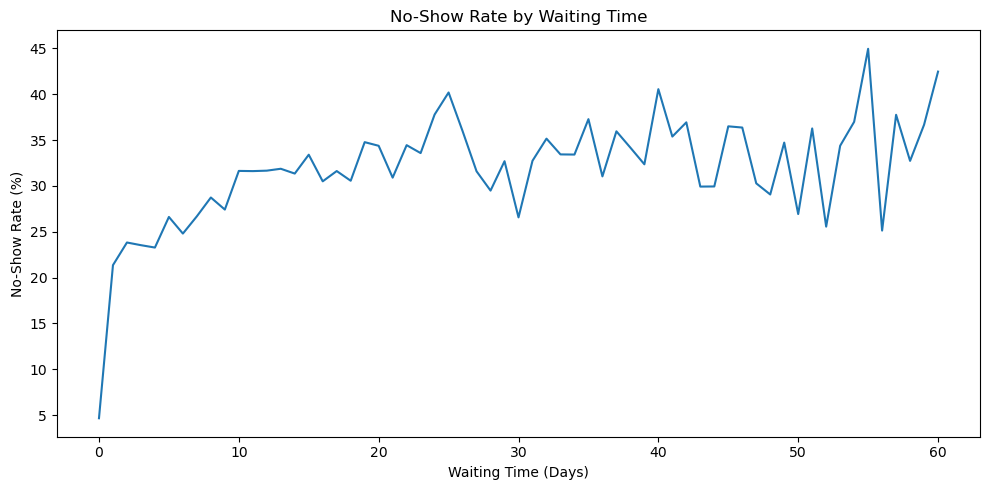

In [28]:
waiting_no_show = (df_analysis.groupby("waiting_days")["no_show"]
    .apply(lambda x: (x == "Yes").mean() * 100))
waiting_no_show = waiting_no_show[waiting_no_show.index <= 60]
plt.figure(figsize=(10, 5))
plt.plot(waiting_no_show.index, waiting_no_show.values)
plt.title("No-Show Rate by Waiting Time")
plt.xlabel("Waiting Time (Days)")
plt.ylabel("No-Show Rate (%)")
plt.tight_layout()
plt.show()

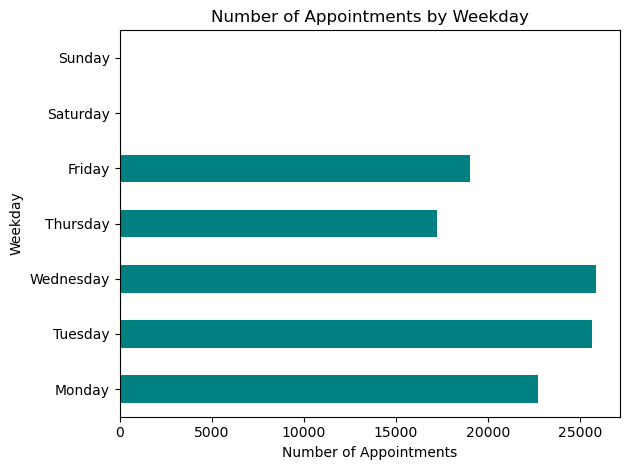

In [29]:
df_analysis["appointment_weekday"] = (df_analysis["appointment_day"].dt.day_name())
weekday_order = ["Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"]
weekday_counts = (df_analysis["appointment_weekday"].value_counts()
    .reindex(weekday_order, fill_value=0))
weekday_counts.plot(kind="barh",color="teal")
plt.title("Number of Appointments by Weekday")
plt.xlabel("Number of Appointments")
plt.ylabel("Weekday")
plt.tight_layout()
plt.show()

## Key Business Insights

1. **Appointment Attendance:** Approximately 79.81% of appointments were attended, while 20.19% were missed. This shows that around one in five appointments was missed.

2. **Gender Analysis:** Female appointments had a no-show rate of 20.31%, compared with 19.96% for male appointments. The difference was small.

3. **Age Group Analysis:** Patients aged 18–35 had the highest no-show rate at 23.81%, while patients aged 56 and above had the lowest rate at 15.64%.

4. **SMS Reminder Analysis:** The no-show rate was 16.70% for appointments without SMS reminders and 27.57% for appointments with SMS reminders. This difference shows an association in the data but does not prove that SMS reminders cause more missed appointments.

5. **Waiting Time Analysis:** The analysis explores the relationship between waiting time and missed appointments. The line chart helps identify how no-show rates vary across different waiting periods, focusing on waiting times up to 60 days.

6. **Weekday Analysis:** The weekday chart compares the number of appointments scheduled on different days. This helps identify busier days and may support better appointment scheduling and resource planning.


## Conclusion

This project analyzed healthcare appointment data using Python, Pandas, NumPy, Matplotlib, and Seaborn.

The analysis found that 79.81% of appointments were attended, while 20.19% were missed. Female appointments had a slightly higher no-show rate than male appointments. Patients aged 18–35 had the highest no-show rate among the age groups analyzed.

The analysis also found that appointments with SMS reminders had a higher no-show rate than appointments without reminders. Waiting time and appointment weekdays were explored to identify additional patterns in appointment attendance.

These findings may help healthcare providers review appointment scheduling, patient communication, and reminder strategies. However, the results show patterns in the available data and do not establish the causes of missed appointments.

Overall, this project demonstrates the use of Python for data cleaning, exploratory data analysis, visualization, and business insight generation.